In [1]:
import sys

print(sys.executable)

c:\BACKUP DATA\customer_risk_prediction\.venv\Scripts\python.exe


In [2]:
import kagglehub

# Login ke Kaggle
kagglehub.login()

In [4]:
import kagglehub
import pandas as pd
from pathlib import Path

# Download dataset dari Kaggle
path = kagglehub.dataset_download(
    "laotse/credit-risk-dataset"
)

print("Dataset berhasil diunduh!")
print("Lokasi:", path)

# Cari file CSV
files = list(Path(path).rglob("*.csv"))

print("File ditemukan:", files)

# Baca dataset
df = pd.read_csv(files[0])

# Tampilkan data
print("Ukuran dataset:", df.shape)
display(df.head())

Dataset berhasil diunduh!
Lokasi: C:\Users\Lenovo\.cache\kagglehub\datasets\laotse\credit-risk-dataset\versions\1
File ditemukan: [WindowsPath('C:/Users/Lenovo/.cache/kagglehub/datasets/laotse/credit-risk-dataset/versions/1/credit_risk_dataset.csv')]
Ukuran dataset: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [16]:
# Melihat informasi dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


In [17]:
# Melihat statistik deskriptif
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [18]:
# Memeriksa jumlah missing values
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [19]:
# Memeriksa jumlah data duplikat
df.duplicated().sum()

np.int64(165)

CLEANING DATA
1. Missing values: ada 895 data kosong pada person_emp_lenght dan 3.116 data kosong pada loan_int_rate
2. Data duplikat: ada 165 bari data dulipkat
3. Nilai yang mungkin tidak wajar: usia maksimum 144 tahun dan lama bekerja 123 tahun. Pendapatan maksimum juga mencapai 6.000.000, sehingga perlu diperiksa sebelum diputuskan sebagai outlier 

In [20]:
# Membuat salinan dataset
df_clean = df.copy()

# Melihat ukuran dataset sebelum cleaning
print("Ukuran data sebelum cleaning:", df_clean.shape)

Ukuran data sebelum cleaning: (32581, 12)


In [21]:
# Menghapus data duplikat
df_clean = df_clean.drop_duplicates()

# Memeriksa kembali jumlah duplikat
print("Jumlah duplikat:", df_clean.duplicated().sum())

# Melihat ukuran data setelah penghapusan duplikat
print("Ukuran data setelah menghapus duplikat:", df_clean.shape)

Jumlah duplikat: 0
Ukuran data setelah menghapus duplikat: (32416, 12)


In [22]:
# Memeriksa usia di atas 100 tahun
print("Usia di atas 100 tahun:")
display(df_clean[df_clean["person_age"] > 100])

# Memeriksa lama bekerja di atas 60 tahun
print("Lama bekerja di atas 60 tahun:")
display(df_clean[df_clean["person_emp_length"] > 60])

# Memeriksa pendapatan di atas 1 juta
print("Pendapatan di atas 1 juta:")
display(df_clean[df_clean["person_income"] > 1_000_000])

Usia di atas 100 tahun:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,NaN,0,0.26,N,4
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25


Lama bekerja di atas 60 tahun:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
210,21,192000,MORTGAGE,123.0,VENTURE,A,20000,6.54,0,0.10,N,4


Pendapatan di atas 1 juta:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
17833,32,1200000,MORTGAGE,1.0,VENTURE,A,12000,7.51,0,0.01,N,8
29119,36,1200000,OWN,16.0,MEDICAL,A,10000,6.54,0,0.01,N,11
29120,40,1200000,MORTGAGE,1.0,MEDICAL,A,10000,NaN,0,0.01,N,16
30049,42,2039784,RENT,0.0,VENTURE,C,8450,12.29,0,0.00,Y,15
31922,47,1362000,MORTGAGE,9.0,VENTURE,A,6600,7.74,0,0.00,N,17
31924,44,1440000,MORTGAGE,7.0,DEBTCONSOLIDATION,A,6400,7.40,0,0.00,N,15
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25
32497,63,1782000,RENT,13.0,EDUCATION,C,12025,14.27,0,0.01,N,30
32546,60,1900000,MORTGAGE,5.0,PERSONAL,A,1500,NaN,0,0.00,N,21


In [23]:
# Menghitung jumlah missing values
missing_values = df_clean.isnull().sum()

# Menghitung persentase missing values
missing_percent = (df_clean.isnull().mean() * 100).round(2)

# Membuat tabel missing values
missing_table = pd.DataFrame({
    "Jumlah Missing": missing_values,
    "Persentase (%)": missing_percent
})

display(missing_table[missing_table["Jumlah Missing"] > 0])

,Jumlah Missing,Persentase (%)
person_emp_length,887,2.74
loan_int_rate,3095,9.55


In [24]:
# Menghitung jumlah masing-masing kategori loan_status
print(df_clean["loan_status"].value_counts())

# Menghitung persentase masing-masing kategori
print("\nPersentase loan_status:")
print((df_clean["loan_status"].value_counts(normalize=True) * 100).round(2))

loan_status
0    25327
1     7089
Name: count, dtype: int64

Persentase loan_status:
loan_status
0    78.13
1    21.87
Name: proportion, dtype: float64


In [25]:
import numpy as np
# Menghapus data dengan usia di atas 100 tahun
df_clean = df_clean[df_clean["person_age"] <= 100].copy()

# Mengubah lama bekerja yang tidak wajar menjadi missing value
df_clean.loc[
    df_clean["person_emp_length"] > 60,
    "person_emp_length"
] = np.nan

# Memeriksa kembali nilai maksimum
print("Usia maksimum:", df_clean["person_age"].max())
print("Lama bekerja maksimum:", df_clean["person_emp_length"].max())

# Melihat ukuran dataset
print("Ukuran dataset setelah pemeriksaan outlier:", df_clean.shape)

Usia maksimum: 94
Lama bekerja maksimum: 41.0
Ukuran dataset setelah pemeriksaan outlier: (32411, 12)


In [26]:
# Menghitung batas outlier menggunakan IQR
Q1 = df_clean["person_income"].quantile(0.25)
Q3 = df_clean["person_income"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

# Menghitung jumlah outlier
outliers_income = df_clean[
    (df_clean["person_income"] < lower_bound) |
    (df_clean["person_income"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Batas bawah:", lower_bound)
print("Batas atas:", upper_bound)
print("Jumlah outlier:", len(outliers_income))
print("Persentase outlier:",
      round(len(outliers_income) / len(df_clean) * 100, 2), "%")

Q1: 38500.0
Q3: 79200.0
IQR: 40700.0
Batas bawah: -22550.0
Batas atas: 140250.0
Jumlah outlier: 1475
Persentase outlier: 4.55 %


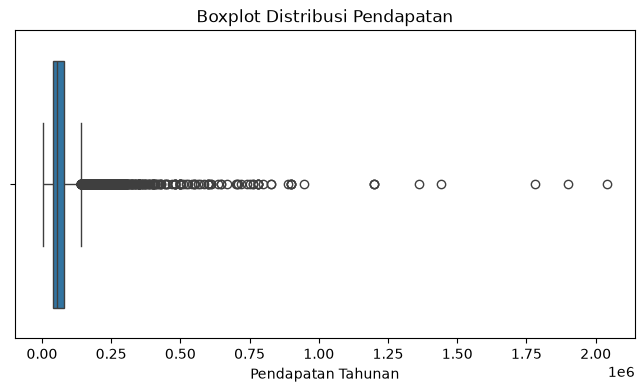

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.boxplot(x=df_clean["person_income"])

plt.title("Boxplot Distribusi Pendapatan")
plt.xlabel("Pendapatan Tahunan")
plt.show()

In [28]:
df_clean.nlargest(10, "person_income")[
    ["person_age", "person_income", "loan_amnt", "loan_status"]
]

,person_age,person_income,loan_amnt,loan_status
30049,42,2039784,8450,0
32546,60,1900000,1500,0
32497,63,1782000,12025,0
31924,44,1440000,6400,0
31922,47,1362000,6600,0
17833,32,1200000,12000,0
29119,36,1200000,10000,0
29120,40,1200000,10000,0
17834,34,948000,2000,0
29121,50,900000,30000,0


In [29]:
df_clean.to_csv(
    "../output/credit_risk_cleaned.csv",
    index=False
)

print("Dataset berhasil disimpan!")
print("Ukuran akhir sementara:", df_clean.shape)

Dataset berhasil disimpan!
Ukuran akhir sementara: (32411, 12)


MENYIAPKAN DATASET UNTUK MELAKUKAN EDA

In [30]:
# Membuat salinan untuk kebutuhan EDA
df_eda = df_clean.copy()

# Mengisi missing values dengan median
df_eda["person_emp_length"] = df_eda["person_emp_length"].fillna(
    df_eda["person_emp_length"].median()
)

df_eda["loan_int_rate"] = df_eda["loan_int_rate"].fillna(
    df_eda["loan_int_rate"].median()
)

# Memeriksa kembali missing values
print("Missing values setelah imputasi:")
print(df_eda.isnull().sum().sum())

print("Ukuran dataset EDA:", df_eda.shape)

Missing values setelah imputasi:
0
Ukuran dataset EDA: (32411, 12)


In [31]:
df_clean.to_csv(
    "../output/credit_risk_cleaned.csv",
    index=False
)

print("Dataset hasil cleaning berhasil disimpan!")

Dataset hasil cleaning berhasil disimpan!


ANALISIS EDA

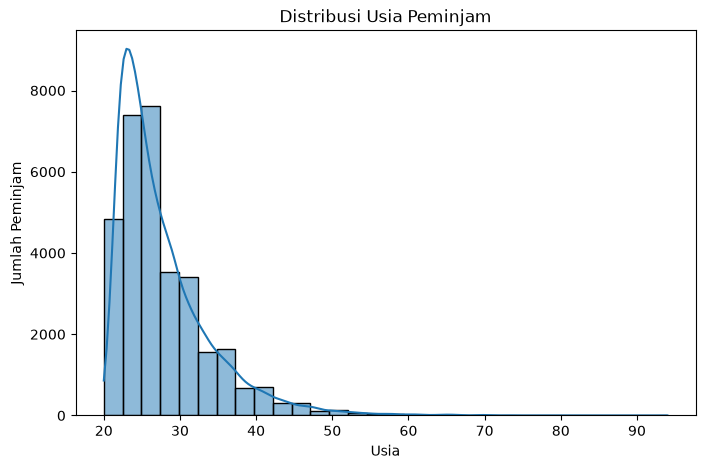

In [32]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_eda,
    x="person_age",
    bins=30,
    kde=True
)

plt.title("Distribusi Usia Peminjam")
plt.xlabel("Usia")
plt.ylabel("Jumlah Peminjam")
plt.show()

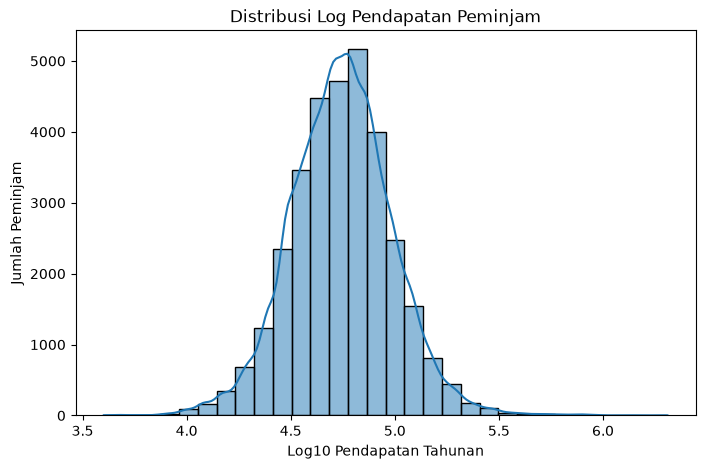

In [33]:
# Membuat kolom log pendapatan
df_eda["log_income"] = np.log10(df_eda["person_income"])

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_eda,
    x="log_income",
    bins=30,
    kde=True
)

plt.title("Distribusi Log Pendapatan Peminjam")
plt.xlabel("Log10 Pendapatan Tahunan")
plt.ylabel("Jumlah Peminjam")

plt.show()

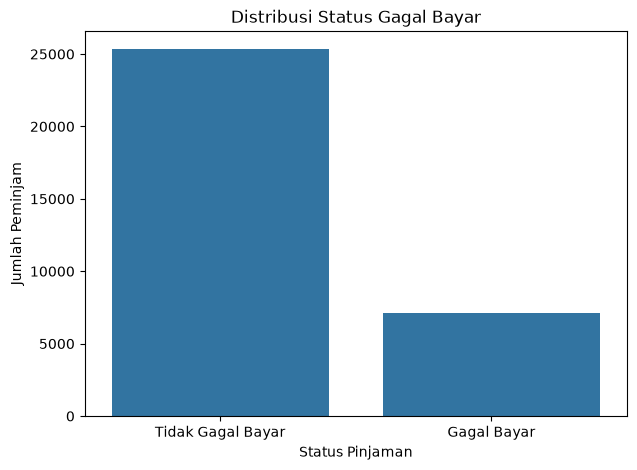

In [34]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_eda,
    x="loan_status"
)

plt.title("Distribusi Status Gagal Bayar")
plt.xlabel("Status Pinjaman")
plt.ylabel("Jumlah Peminjam")

plt.xticks(
    ticks=[0, 1],
    labels=["Tidak Gagal Bayar", "Gagal Bayar"]
)

plt.show()

In [35]:
df_eda[
    [
        "person_age",
        "person_income",
        "person_emp_length",
        "loan_amnt",
        "loan_int_rate",
        "loan_percent_income"
    ]
].describe().round(2)

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income
count,32411.00,32411.00,32411.00,32411.00,32411.00,32411.00
mean,27.73,65897.96,4.76,9593.59,11.01,0.17
std,6.21,52520.93,3.98,6322.53,3.08,0.11
min,20.00,4000.00,0.00,500.00,5.42,0.00
25%,23.00,38500.00,2.00,5000.00,8.49,0.09
50%,26.00,55000.00,4.00,8000.00,10.99,0.15
75%,30.00,79200.00,7.00,12250.00,13.11,0.23
max,94.00,2039784.00,41.00,35000.00,23.22,0.83


ANALISIS HUBUNGAN DENGAN RESIKO GAGAL BAYAR:
1. Berdasarkan usia
2. Berdasarkan kepemilikan rumah
3. Berdasarkan tujuan peminjaman

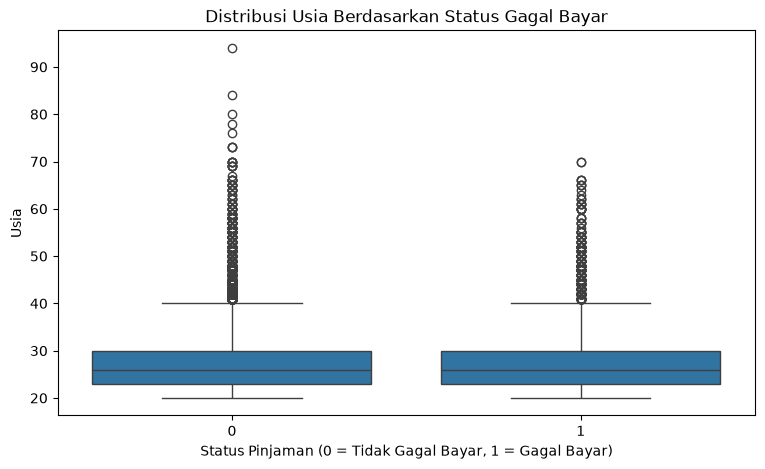

In [36]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_eda,
    x="loan_status",
    y="person_age"
)

plt.title("Distribusi Usia Berdasarkan Status Gagal Bayar")
plt.xlabel("Status Pinjaman (0 = Tidak Gagal Bayar, 1 = Gagal Bayar)")
plt.ylabel("Usia")

plt.show()

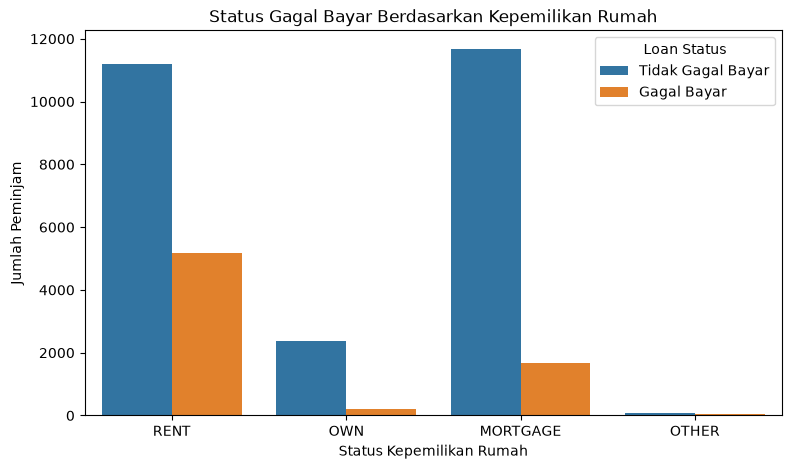

In [37]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_eda,
    x="person_home_ownership",
    hue="loan_status"
)

plt.title("Status Gagal Bayar Berdasarkan Kepemilikan Rumah")
plt.xlabel("Status Kepemilikan Rumah")
plt.ylabel("Jumlah Peminjam")
plt.legend(
    title="Loan Status",
    labels=["Tidak Gagal Bayar", "Gagal Bayar"]
)

plt.show()

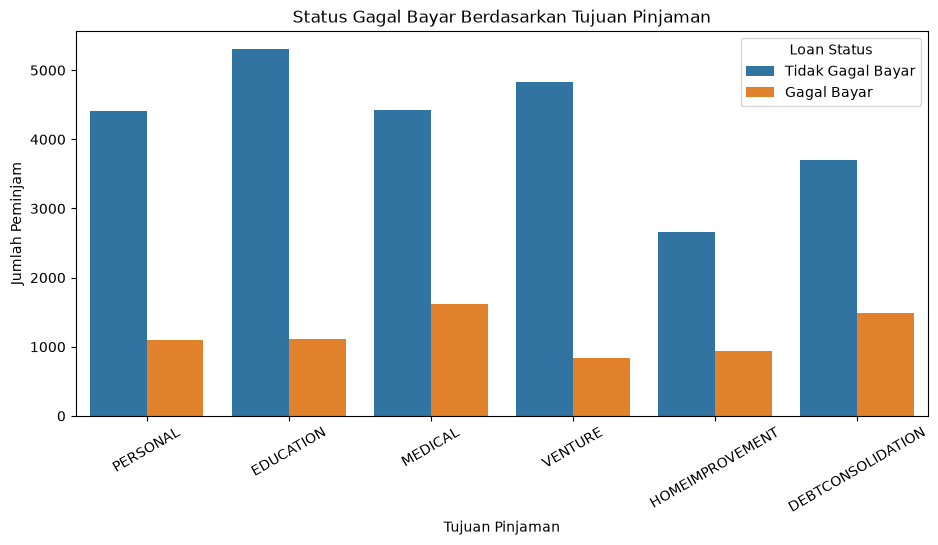

In [38]:
plt.figure(figsize=(11, 5))

sns.countplot(
    data=df_eda,
    x="loan_intent",
    hue="loan_status"
)

plt.title("Status Gagal Bayar Berdasarkan Tujuan Pinjaman")
plt.xlabel("Tujuan Pinjaman")
plt.ylabel("Jumlah Peminjam")
plt.xticks(rotation=30)

plt.legend(
    title="Loan Status",
    labels=["Tidak Gagal Bayar", "Gagal Bayar"]
)

plt.show()

MENGHITUNG PERSENTASE RISIKO GAGAL BAYAR

In [39]:
# Menghitung rata-rata loan_status berdasarkan kepemilikan rumah
home_default_rate = (
    df_eda.groupby("person_home_ownership")["loan_status"]
    .mean() * 100
).sort_values(ascending=False)

print("Default Rate Berdasarkan Kepemilikan Rumah:")
display(home_default_rate.round(2))

Default Rate Berdasarkan Kepemilikan Rumah:


person_home_ownership
RENT        31.62
OTHER       31.13
MORTGAGE    12.62
OWN          7.49
Name: loan_status, dtype: float64

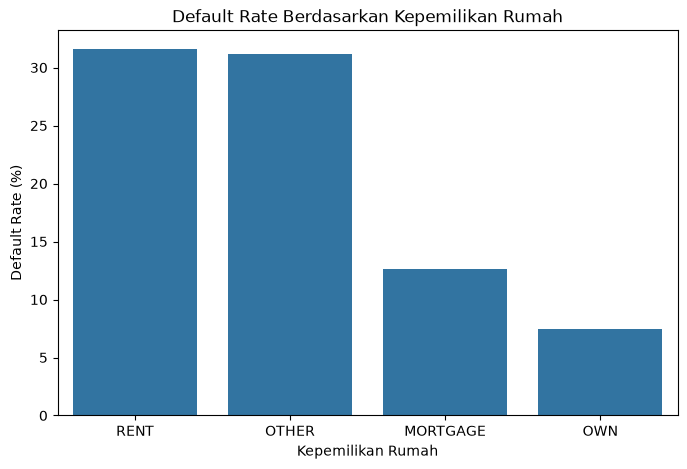

In [40]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=home_default_rate.index,
    y=home_default_rate.values
)

plt.title("Default Rate Berdasarkan Kepemilikan Rumah")
plt.xlabel("Kepemilikan Rumah")
plt.ylabel("Default Rate (%)")

plt.show()

In [41]:
# Default rate dan jumlah peminjam berdasarkan kepemilikan rumah
home_analysis = df_eda.groupby(
    "person_home_ownership"
).agg(
    total_peminjam=("loan_status", "count"),
    jumlah_gagal_bayar=("loan_status", "sum"),
    default_rate=("loan_status", "mean")
)

home_analysis["default_rate"] *= 100

display(home_analysis.round(2))

,total_peminjam,jumlah_gagal_bayar,default_rate
person_home_ownership,,,
MORTGAGE,13367,1687,12.62
OTHER,106,33,31.13
OWN,2563,192,7.49
RENT,16375,5177,31.62


In [42]:
# Menghitung rata-rata loan_status berdasarkan tujuan pinjaman
intent_default_rate = (
    df_eda.groupby("loan_intent")["loan_status"]
    .mean() * 100
).sort_values(ascending=False)

print("Default Rate Berdasarkan Tujuan Pinjaman:")
display(intent_default_rate.round(2))

Default Rate Berdasarkan Tujuan Pinjaman:


loan_intent
DEBTCONSOLIDATION    28.68
MEDICAL              26.76
HOMEIMPROVEMENT      26.15
PERSONAL             19.90
EDUCATION            17.26
VENTURE              14.86
Name: loan_status, dtype: float64

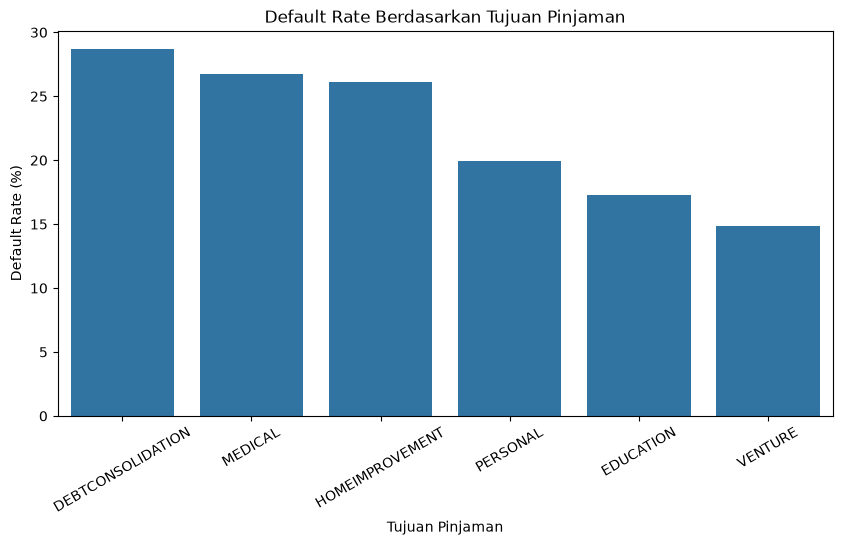

In [43]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=intent_default_rate.index,
    y=intent_default_rate.values
)

plt.title("Default Rate Berdasarkan Tujuan Pinjaman")
plt.xlabel("Tujuan Pinjaman")
plt.ylabel("Default Rate (%)")

plt.xticks(rotation=30)

plt.show()

In [44]:
# Default rate dan jumlah peminjam berdasarkan tujuan pinjaman
intent_analysis = df_eda.groupby(
    "loan_intent"
).agg(
    total_peminjam=("loan_status", "count"),
    jumlah_gagal_bayar=("loan_status", "sum"),
    default_rate=("loan_status", "mean")
)

intent_analysis["default_rate"] *= 100

display(intent_analysis.round(2))

,total_peminjam,jumlah_gagal_bayar,default_rate
loan_intent,,,
DEBTCONSOLIDATION,5189,1488,28.68
EDUCATION,6409,1106,17.26
HOMEIMPROVEMENT,3594,940,26.15
MEDICAL,6042,1617,26.76
PERSONAL,5497,1094,19.90
VENTURE,5680,844,14.86


In [45]:
# Membuat kelompok usia
df_eda["age_group"] = pd.cut(
    df_eda["person_age"],
    bins=[19, 25, 35, 45, 55, 100],
    labels=[
        "20-25",
        "26-35",
        "36-45",
        "46-55",
        "56+"
    ]
)

# Menghitung default rate berdasarkan kelompok usia
age_default_rate = (
    df_eda.groupby("age_group", observed=False)["loan_status"]
    .mean() * 100
)

print("Default Rate Berdasarkan Kelompok Usia:")
display(age_default_rate.round(2))

Default Rate Berdasarkan Kelompok Usia:


age_group
20-25    23.14
26-35    20.69
36-45    20.68
46-55    21.88
56+      23.88
Name: loan_status, dtype: float64

ANALISIS VARIABEL NUMERIK:
1. Persentase pinjaman terhadap pendapatan (loan_percent_income)
2. Tingkat bunga pinjaman (loan_int_rate)
3. Panjang riwayat kredit (cb_person_cred_hist_length)

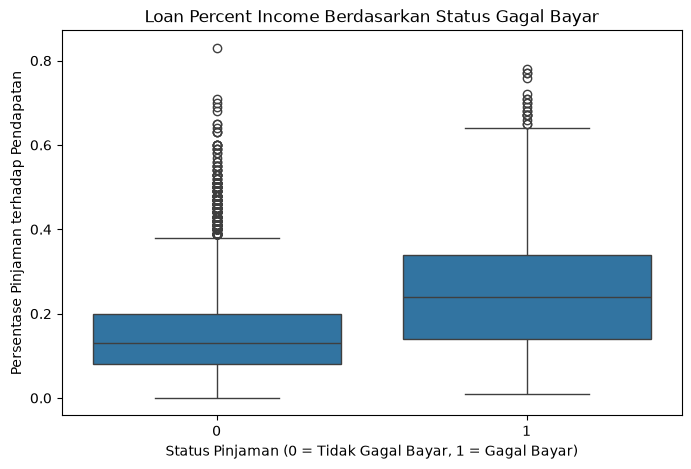

In [46]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_eda,
    x="loan_status",
    y="loan_percent_income"
)

plt.title("Loan Percent Income Berdasarkan Status Gagal Bayar")
plt.xlabel("Status Pinjaman (0 = Tidak Gagal Bayar, 1 = Gagal Bayar)")
plt.ylabel("Persentase Pinjaman terhadap Pendapatan")

plt.show()

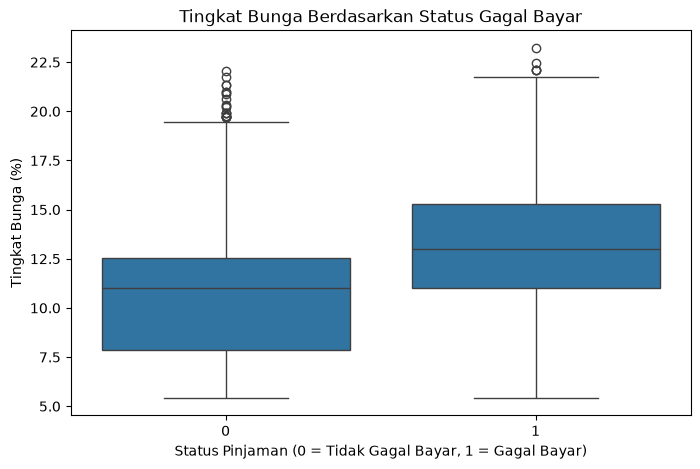

In [47]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_eda,
    x="loan_status",
    y="loan_int_rate"
)

plt.title("Tingkat Bunga Berdasarkan Status Gagal Bayar")
plt.xlabel("Status Pinjaman (0 = Tidak Gagal Bayar, 1 = Gagal Bayar)")
plt.ylabel("Tingkat Bunga (%)")

plt.show()

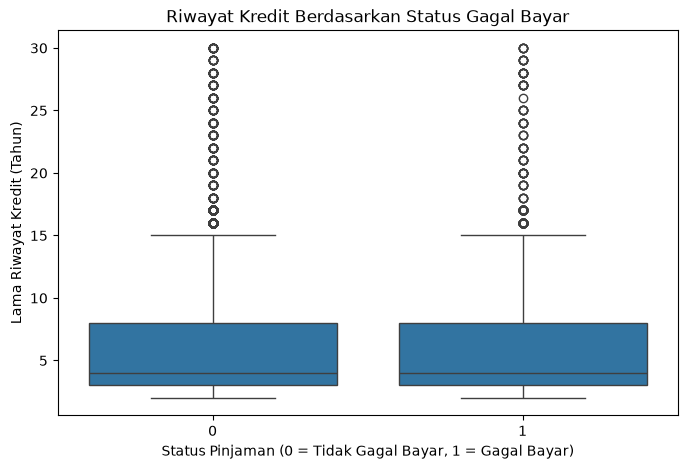

In [48]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_eda,
    x="loan_status",
    y="cb_person_cred_hist_length"
)

plt.title("Riwayat Kredit Berdasarkan Status Gagal Bayar")
plt.xlabel("Status Pinjaman (0 = Tidak Gagal Bayar, 1 = Gagal Bayar)")
plt.ylabel("Lama Riwayat Kredit (Tahun)")

plt.show()

CORRELATION HEATMAP

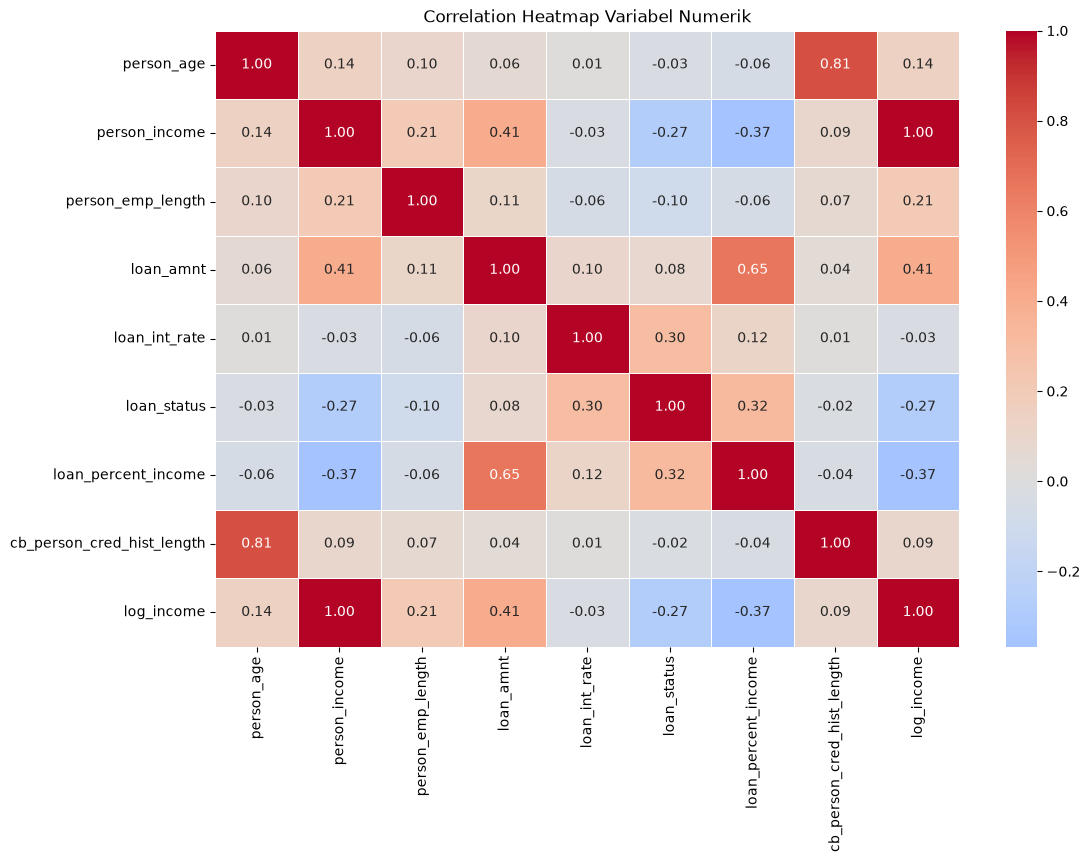

In [49]:
# Memilih kolom numerik
numeric_df = df_eda.select_dtypes(include=["number"])

# Menghitung korelasi Spearman
correlation = numeric_df.corr(method="spearman")

# Membuat visualisasi heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap Variabel Numerik")
plt.show()

Persiapan Model Prediksi Menggunakan Machine Learning:
1. Logistic Regression
2. Decision Tree
3. Random Forest

In [56]:
# Cek ukuran dataset hasil cleaning
print("Ukuran dataset:", df_clean.shape)

Ukuran dataset: (32411, 12)


In [57]:
from sklearn.model_selection import train_test_split

# Membagi dataset menjadi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Melihat ukuran data
print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test:", X_test.shape)
print("Ukuran y_train:", y_train.shape)
print("Ukuran y_test:", y_test.shape)

Ukuran X_train: (25928, 9)
Ukuran X_test: (6483, 9)
Ukuran y_train: (25928,)
Ukuran y_test: (6483,)


DATA PREPROCESSING

In [58]:
# Memisahkan kolom numerik dan kategorikal

numeric_features = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_percent_income",
    "cb_person_cred_hist_length"
]

categorical_features = [
    "person_home_ownership",
    "loan_intent",
    "cb_person_default_on_file"
]

print("Fitur Numerik:")
print(numeric_features)

print("\nFitur Kategorikal:")
print(categorical_features)

Fitur Numerik:
['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_percent_income', 'cb_person_cred_hist_length']

Fitur Kategorikal:
['person_home_ownership', 'loan_intent', 'cb_person_default_on_file']


In [59]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Pipeline untuk fitur numerik
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline untuk fitur kategorikal
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Menggabungkan preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline berhasil dibuat.")

Preprocessing pipeline berhasil dibuat.


In [60]:
# Melakukan preprocessing pada data training dan testing

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Ukuran data training setelah preprocessing:",
      X_train_processed.shape)

print("Ukuran data testing setelah preprocessing:",
      X_test_processed.shape)

Ukuran data training setelah preprocessing: (25928, 18)
Ukuran data testing setelah preprocessing: (6483, 18)


MODEL MACHINE LEARNING: LOGISTIC REGRESSION

In [62]:
from sklearn.linear_model import LogisticRegression

# Membuat model Logistic Regression
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

print("Model Logistic Regression berhasil dibuat.")

# Melatih model menggunakan data training
logistic_model.fit(
    X_train_processed,
    y_train
)

print("Model Logistic Regression berhasil dilatih.")

# Melakukan prediksi pada data testing
y_pred = logistic_model.predict(X_test_processed)

# Melihat 20 hasil prediksi pertama
print("Hasil prediksi:")
print(y_pred[:20])



Model Logistic Regression berhasil dibuat.
Model Logistic Regression berhasil dilatih.
Hasil prediksi:
[0 0 0 0 1 0 0 0 1 1 0 1 0 0 0 1 0 0 0 1]


TAHAP EVALUASI LOGISTIC REGRESSION

In [63]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Menghitung probabilitas prediksi kelas default
y_prob = logistic_model.predict_proba(X_test_processed)[:, 1]

# Menghitung metrik evaluasi
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)

# Menampilkan hasil evaluasi
print("=== HASIL EVALUASI LOGISTIC REGRESSION ===")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print(f"PR-AUC    : {pr_auc:.4f}")

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-Default (0)", "Default (1)"]
))

print("\n=== CONFUSION MATRIX ===")
print(confusion_matrix(y_test, y_pred))

=== HASIL EVALUASI LOGISTIC REGRESSION ===
Accuracy  : 0.7399
Precision : 0.4409
Recall    : 0.7045
F1-Score  : 0.5423
ROC-AUC   : 0.8017
PR-AUC    : 0.6139

=== CLASSIFICATION REPORT ===
                 precision    recall  f1-score   support

Non-Default (0)       0.90      0.75      0.82      5065
    Default (1)       0.44      0.70      0.54      1418

       accuracy                           0.74      6483
      macro avg       0.67      0.73      0.68      6483
   weighted avg       0.80      0.74      0.76      6483


=== CONFUSION MATRIX ===
[[3798 1267]
 [ 419  999]]


GRAFIK CONFUSION MATRIX, ROC CURVE, PRECISION-RECALL CURVE, PERBANDINGAN METRIK EVLUASI

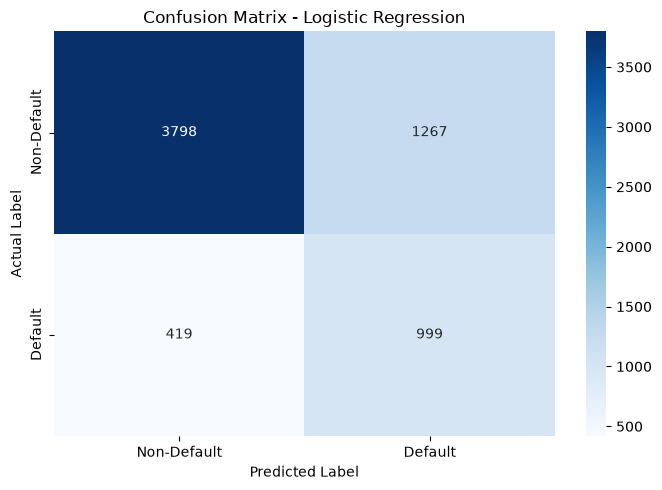

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

# Membuat Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Default", "Default"],
    yticklabels=["Non-Default", "Default"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

MODEL MACHINE LEARNING: DECISION TREE

In [66]:
from sklearn.tree import DecisionTreeClassifier

# Membuat model Decision Tree
decision_tree_model = DecisionTreeClassifier(
    max_depth=6,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

# Melatih model
decision_tree_model.fit(
    X_train_processed,
    y_train
)

print("Model Decision Tree berhasil dilatih.")

# Prediksi kelas
y_pred_dt = decision_tree_model.predict(X_test_processed)

# Prediksi probabilitas default
y_prob_dt = decision_tree_model.predict_proba(
    X_test_processed
)[:, 1]

print("Hasil prediksi Decision Tree:")
print(y_pred_dt[:20])

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# Menghitung metrik evaluasi
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
roc_auc_dt = roc_auc_score(y_test, y_prob_dt)
pr_auc_dt = average_precision_score(y_test, y_prob_dt)

print("=== HASIL EVALUASI DECISION TREE ===")
print(f"Accuracy  : {accuracy_dt:.4f}")
print(f"Precision : {precision_dt:.4f}")
print(f"Recall    : {recall_dt:.4f}")
print(f"F1-Score  : {f1_dt:.4f}")
print(f"ROC-AUC   : {roc_auc_dt:.4f}")
print(f"PR-AUC    : {pr_auc_dt:.4f}")

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=["Non-Default (0)", "Default (1)"]
))

print("\n=== CONFUSION MATRIX ===")
print(confusion_matrix(y_test, y_pred_dt))

Model Decision Tree berhasil dilatih.
Hasil prediksi Decision Tree:
[0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0]
=== HASIL EVALUASI DECISION TREE ===
Accuracy  : 0.8635
Precision : 0.7382
Recall    : 0.5825
F1-Score  : 0.6512
ROC-AUC   : 0.8425
PR-AUC    : 0.7219

=== CLASSIFICATION REPORT ===
                 precision    recall  f1-score   support

Non-Default (0)       0.89      0.94      0.92      5065
    Default (1)       0.74      0.58      0.65      1418

       accuracy                           0.86      6483
      macro avg       0.81      0.76      0.78      6483
   weighted avg       0.86      0.86      0.86      6483


=== CONFUSION MATRIX ===
[[4772  293]
 [ 592  826]]


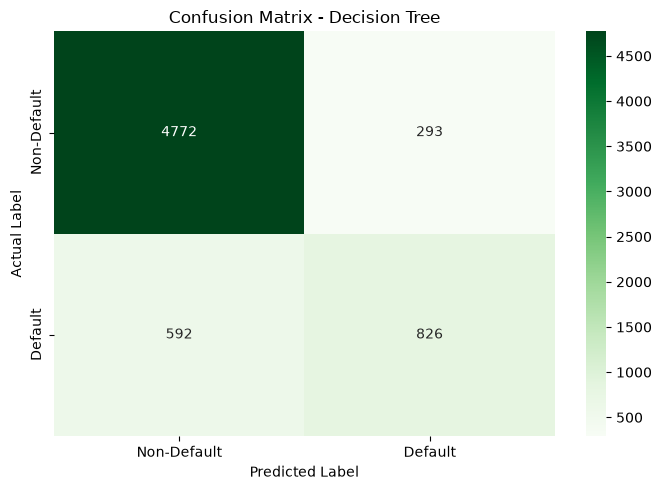

In [67]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    confusion_matrix(y_test, y_pred_dt),
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Non-Default", "Default"],
    yticklabels=["Non-Default", "Default"]
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

MODEL MACHINE LEARNING: RANDOM FOREST

In [70]:
from sklearn.ensemble import RandomForestClassifier

# Membuat model Random Forest
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Melatih model
random_forest_model.fit(
    X_train_processed,
    y_train
)

print("Model Random Forest berhasil dilatih.")

# Prediksi kelas
y_pred_rf = random_forest_model.predict(X_test_processed)

# Prediksi probabilitas default
y_prob_rf = random_forest_model.predict_proba(
    X_test_processed
)[:, 1]

print("Hasil prediksi Random Forest:")
print(y_pred_rf[:20])

# Menghitung metrik evaluasi
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)
pr_auc_rf = average_precision_score(y_test, y_prob_rf)

print("=== HASIL EVALUASI RANDOM FOREST ===")
print(f"Accuracy  : {accuracy_rf:.4f}")
print(f"Precision : {precision_rf:.4f}")
print(f"Recall    : {recall_rf:.4f}")
print(f"F1-Score  : {f1_rf:.4f}")
print(f"ROC-AUC   : {roc_auc_rf:.4f}")
print(f"PR-AUC    : {pr_auc_rf:.4f}")

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Non-Default (0)", "Default (1)"]
))

print("\n=== CONFUSION MATRIX ===")
print(confusion_matrix(y_test, y_pred_rf))

Model Random Forest berhasil dilatih.
Hasil prediksi Random Forest:
[0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 1]
=== HASIL EVALUASI RANDOM FOREST ===
Accuracy  : 0.8413
Precision : 0.6272
Recall    : 0.6763
F1-Score  : 0.6508
ROC-AUC   : 0.8662
PR-AUC    : 0.7726

=== CLASSIFICATION REPORT ===
                 precision    recall  f1-score   support

Non-Default (0)       0.91      0.89      0.90      5065
    Default (1)       0.63      0.68      0.65      1418

       accuracy                           0.84      6483
      macro avg       0.77      0.78      0.77      6483
   weighted avg       0.85      0.84      0.84      6483


=== CONFUSION MATRIX ===
[[4495  570]
 [ 459  959]]


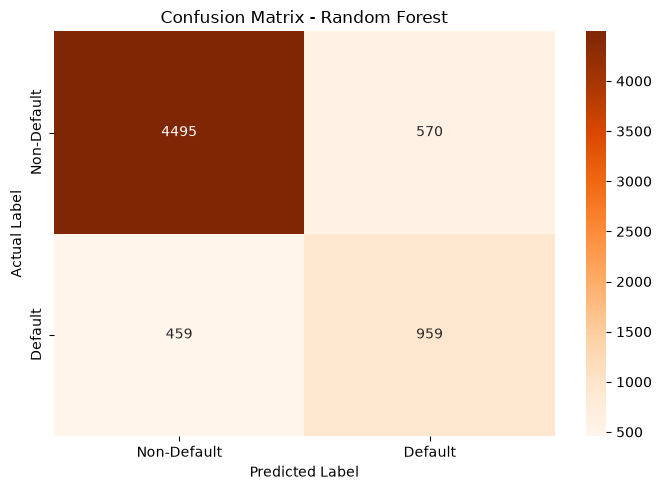

                                Feature  Importance
4              num__loan_percent_income    0.317157
1                    num__person_income    0.213847
9       cat__person_home_ownership_RENT    0.082279
3                        num__loan_amnt    0.077187
17     cat__cb_person_default_on_file_Y    0.051587
16     cat__cb_person_default_on_file_N    0.050111
6   cat__person_home_ownership_MORTGAGE    0.047801
8        cat__person_home_ownership_OWN    0.033968
2                num__person_emp_length    0.022516
15             cat__loan_intent_VENTURE    0.019228


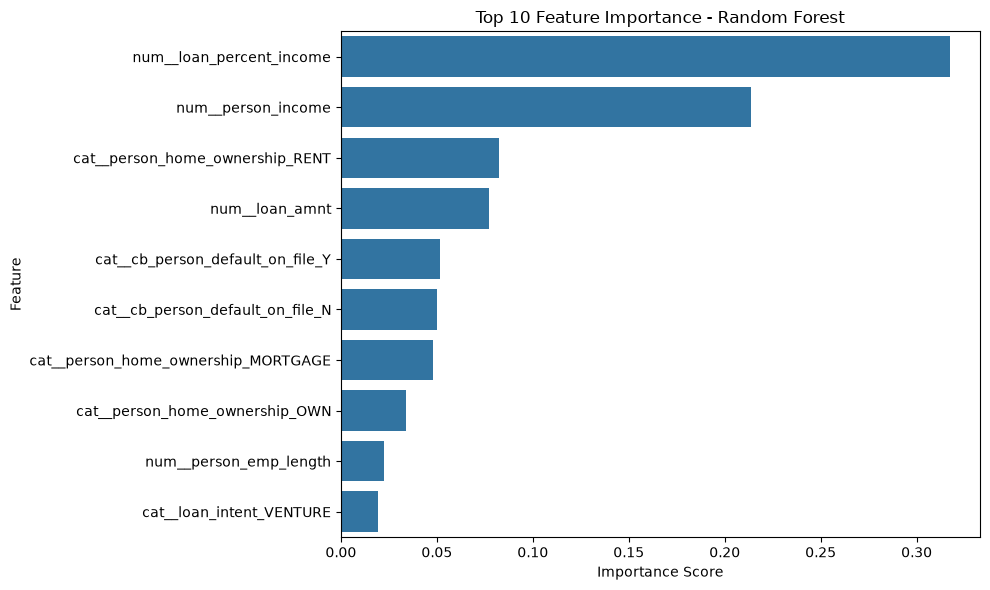

In [71]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    confusion_matrix(y_test, y_pred_rf),
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Non-Default", "Default"],
    yticklabels=["Non-Default", "Default"]
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

# Mengambil nama fitur setelah preprocessing
feature_names = preprocessor.get_feature_names_out()

# Mengambil nilai feature importance
importance = random_forest_model.feature_importances_

# Membuat DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Mengurutkan berdasarkan importance tertinggi
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Menampilkan 10 fitur terpenting
print(feature_importance.head(10))

# Membuat grafik
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

PERBANDINGAN 3 MODEL ML

                 Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC
0  Logistic Regression    0.7399     0.4409  0.7045    0.5423   0.8017  0.6139
1        Decision Tree    0.8635     0.7382  0.5825    0.6512   0.8425  0.7219
2        Random Forest    0.8413     0.6272  0.6763    0.6508   0.8662  0.7726


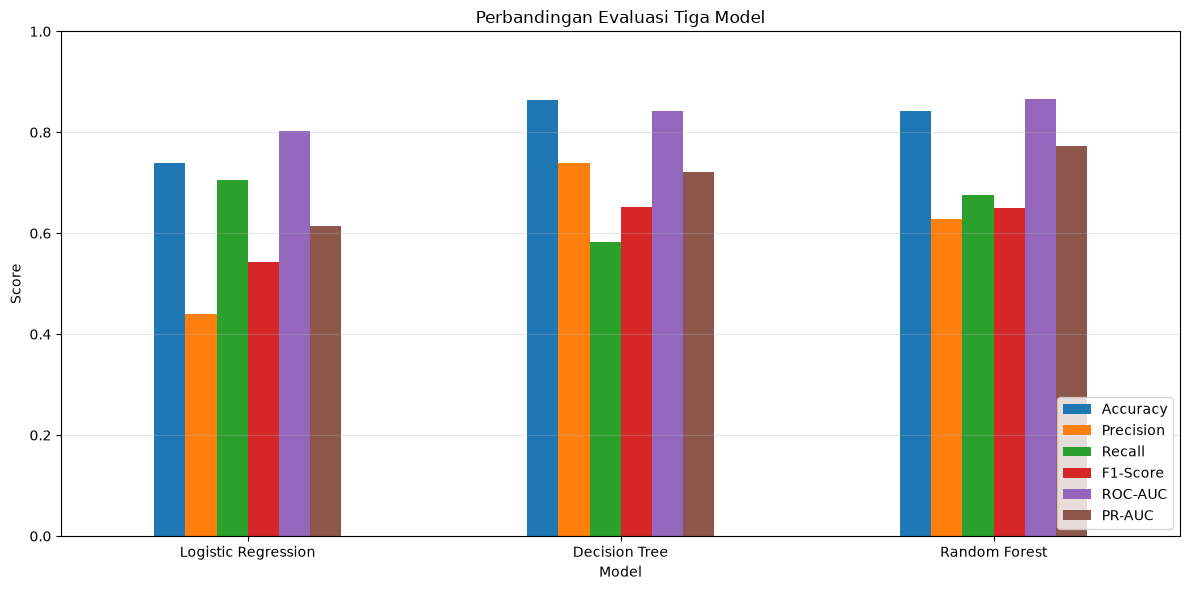

In [73]:
# Membuat tabel perbandingan model

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [accuracy, accuracy_dt, accuracy_rf],
    "Precision": [precision, precision_dt, precision_rf],
    "Recall": [recall, recall_dt, recall_rf],
    "F1-Score": [f1, f1_dt, f1_rf],
    "ROC-AUC": [roc_auc, roc_auc_dt, roc_auc_rf],
    "PR-AUC": [pr_auc, pr_auc_dt, pr_auc_rf]
})

print(comparison.round(4))

comparison_plot = comparison.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Perbandingan Evaluasi Tiga Model")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

CROSS-VALIDATION

In [75]:
from sklearn.model_selection import cross_validate, StratifiedKFold

# Membuat 5-Fold Cross-Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluasi Random Forest menggunakan Cross-Validation
cv_results = cross_validate(
    random_forest_model,
    X_train_processed,
    y_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
    n_jobs=-1
)

# Menampilkan hasil setiap fold
cv_results_df = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "Accuracy": cv_results["test_accuracy"],
    "Precision": cv_results["test_precision"],
    "Recall": cv_results["test_recall"],
    "F1-Score": cv_results["test_f1"],
    "ROC-AUC": cv_results["test_roc_auc"]
})

print("Hasil 5-Fold Cross-Validation:")
display(cv_results_df.round(4))

# Menghitung rata-rata performa
print("\nRata-rata Performa:")
display(cv_results_df.drop(columns="Fold").mean().to_frame(name="Mean").round(4))

# Menghitung standar deviasi
print("\nStandar Deviasi:")
display(cv_results_df.drop(columns="Fold").std().to_frame(name="Std").round(4))

Hasil 5-Fold Cross-Validation:


,Fold,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,1,0.8465,0.6488,0.6499,0.6493,0.8630
1,2,0.8421,0.6309,0.6693,0.6496,0.8647
2,3,0.8508,0.6552,0.6714,0.6632,0.8672
3,4,0.8432,0.6271,0.6984,0.6608,0.8728
4,5,0.8532,0.6618,0.6728,0.6672,0.8730



Rata-rata Performa:


,Mean
Accuracy,0.8472
Precision,0.6447
Recall,0.6724
F1-Score,0.6580
ROC-AUC,0.8681



Standar Deviasi:


,Std
Accuracy,0.0048
Precision,0.0151
Recall,0.0173
F1-Score,0.0082
ROC-AUC,0.0046


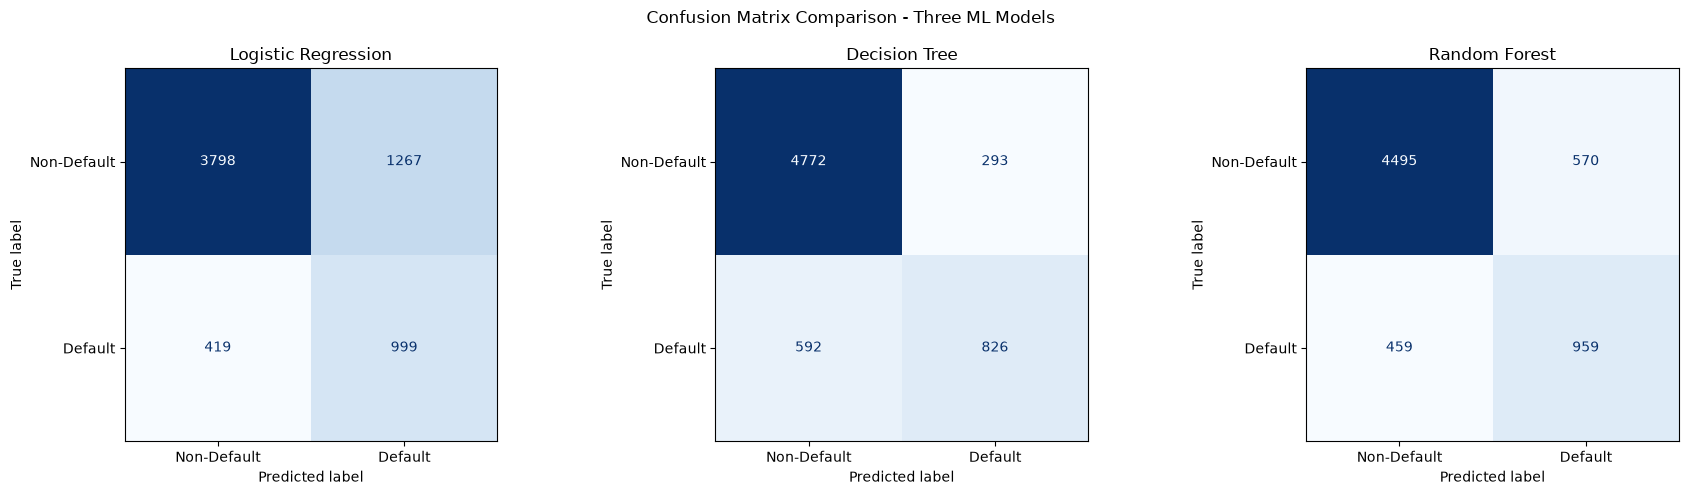

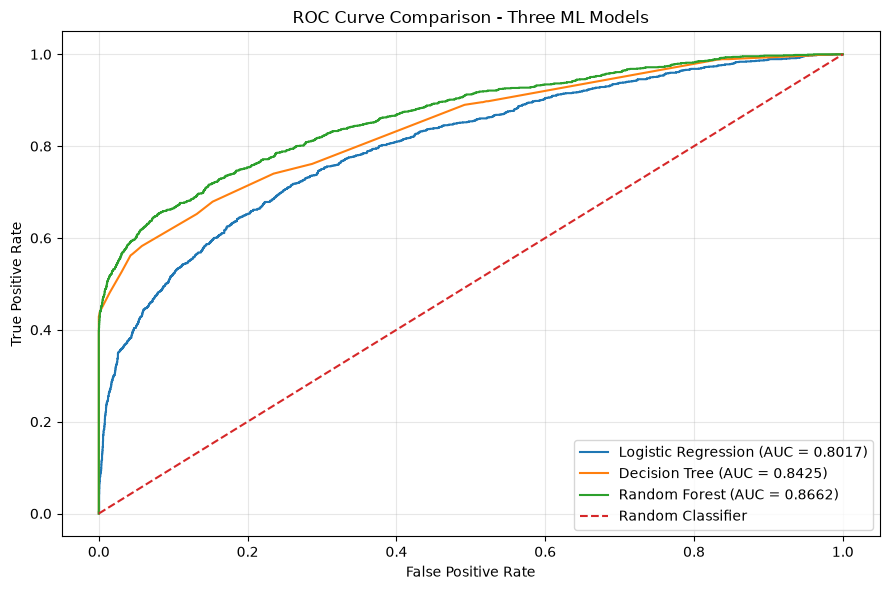

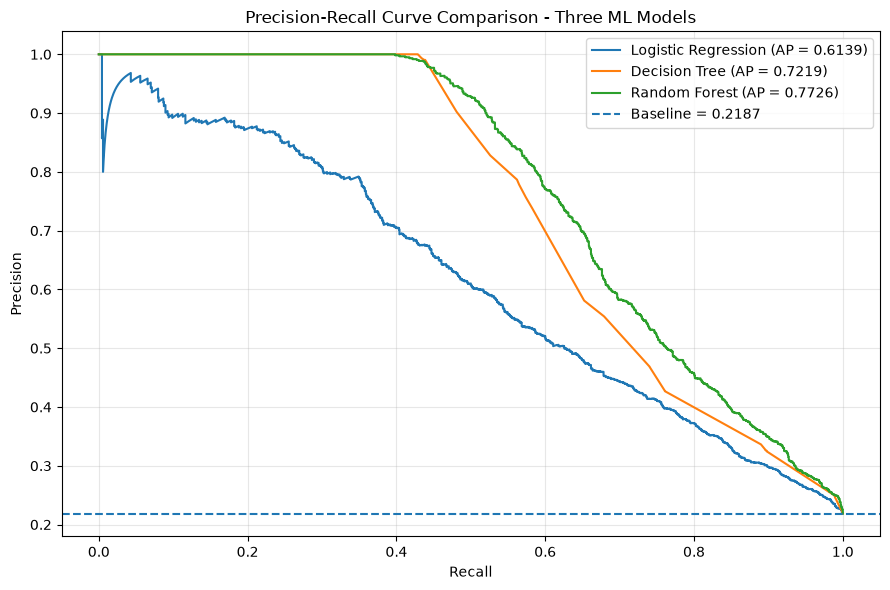

In [79]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Menyiapkan prediksi ketiga model
models = {
    "Logistic Regression": y_pred,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf
}

# Membuat visualisasi Confusion Matrix
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, predictions) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, predictions)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Non-Default", "Default"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(model_name)

plt.suptitle("Confusion Matrix Comparison - Three ML Models")
plt.tight_layout()
plt.show()

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Menghitung ROC Curve masing-masing model
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob)
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

# Menghitung AUC
auc_lr = roc_auc_score(y_test, y_prob)
auc_dt = roc_auc_score(y_test, y_prob_dt)
auc_rf = roc_auc_score(y_test, y_prob_rf)

# Membuat visualisasi
plt.figure(figsize=(9, 6))

plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {auc_lr:.4f})")
plt.plot(fpr_dt, tpr_dt, label=f"Decision Tree (AUC = {auc_dt:.4f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve Comparison - Three ML Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Menghitung Precision-Recall Curve
precision_lr, recall_lr, _ = precision_recall_curve(y_test, y_prob)
precision_dt, recall_dt, _ = precision_recall_curve(y_test, y_prob_dt)
precision_rf, recall_rf, _ = precision_recall_curve(y_test, y_prob_rf)

# Menghitung PR-AUC (Average Precision)
pr_auc_lr = average_precision_score(y_test, y_prob)
pr_auc_dt = average_precision_score(y_test, y_prob_dt)
pr_auc_rf = average_precision_score(y_test, y_prob_rf)

# Membuat visualisasi
plt.figure(figsize=(9, 6))

plt.plot(recall_lr, precision_lr,
         label=f"Logistic Regression (AP = {pr_auc_lr:.4f})")

plt.plot(recall_dt, precision_dt,
         label=f"Decision Tree (AP = {pr_auc_dt:.4f})")

plt.plot(recall_rf, precision_rf,
         label=f"Random Forest (AP = {pr_auc_rf:.4f})")

# Baseline berdasarkan proporsi kelas positif
baseline = y_test.mean()
plt.axhline(y=baseline, linestyle="--",
            label=f"Baseline = {baseline:.4f}")

plt.title("Precision-Recall Curve Comparison - Three ML Models")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [81]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate, StratifiedKFold

# Membuat pipeline Random Forest
final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", random_forest_model)
])

# Membuat 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Melakukan cross-validation
cv_results_final = cross_validate(
    final_model,
    X_train,
    y_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
    n_jobs=1
)

print("Hasil Cross-Validation:")
print("Accuracy :", cv_results_final["test_accuracy"].mean())
print("Precision:", cv_results_final["test_precision"].mean())
print("Recall   :", cv_results_final["test_recall"].mean())
print("F1-Score :", cv_results_final["test_f1"].mean())
print("ROC-AUC  :", cv_results_final["test_roc_auc"].mean())

Hasil Cross-Validation:
Accuracy : 0.8470380421139773
Precision: 0.6444579037900207
Recall   : 0.6721919990055085
F1-Score : 0.657796898827868
ROC-AUC  : 0.8681556862708895
